In [1]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

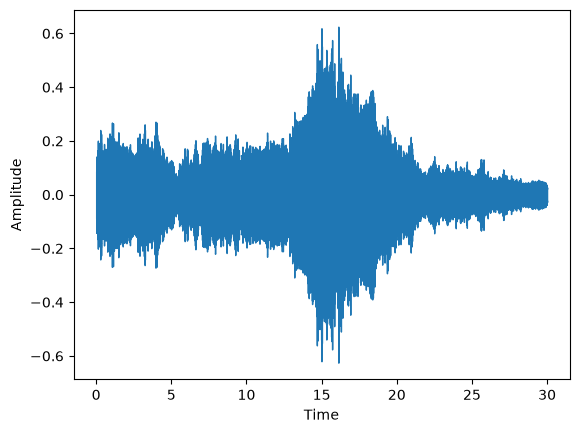

In [2]:
file = "debussy.wav"

signal, sr = librosa.load(file, sr=22050)
librosa.display.waveshow(signal, sr=sr)
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.show()

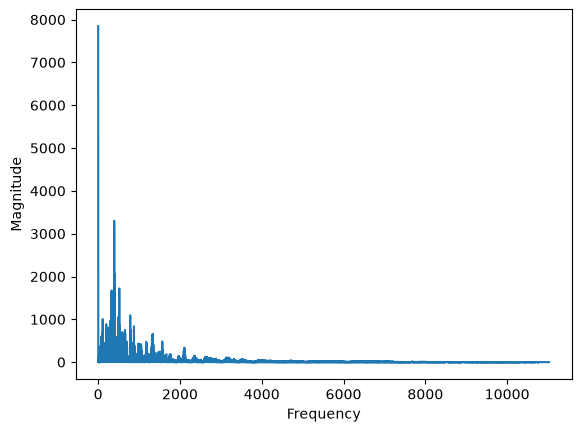

In [6]:
fft = np.fft.fft(signal)

magnitude = np.abs(fft)
frequency = np.linspace(0, sr, len(magnitude))

plt.plot(frequency[:int(len(magnitude)/2)], magnitude[:int(len(magnitude)/2)])
plt.xlabel("Frequency")
plt.ylabel("Magnitude")
plt.show()

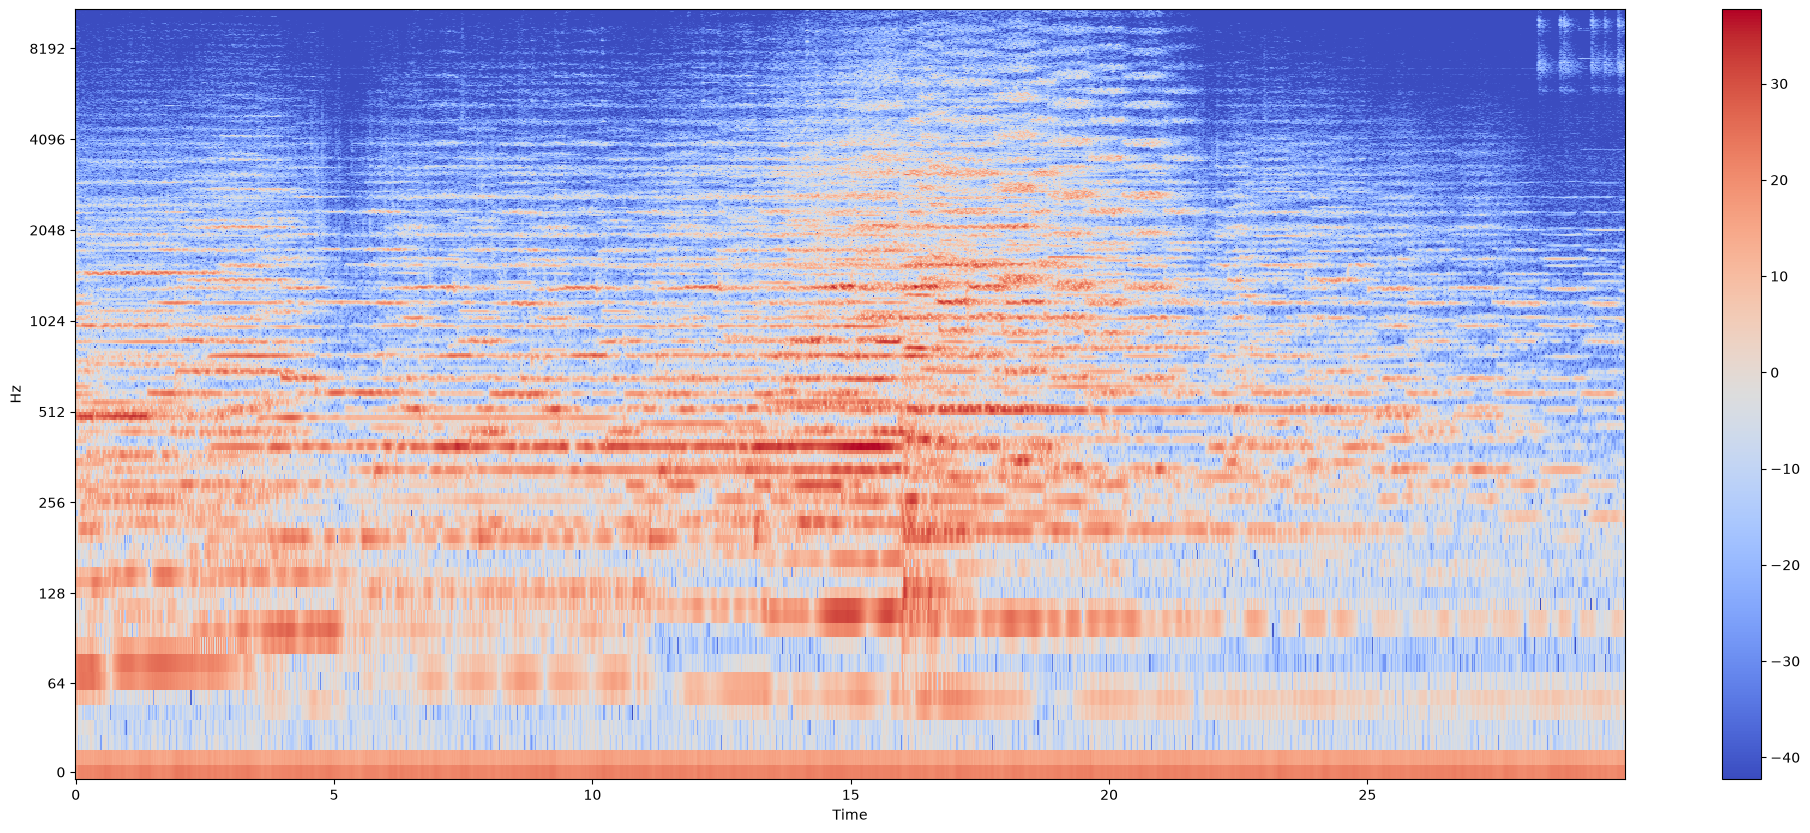

In [11]:
frame_size = 2048 
hop_size = 512

stft = librosa.core.stft(y=signal, n_fft=frame_size, hop_length=hop_size)
spectrogram = np.abs(stft)
log_spectrogram = librosa.amplitude_to_db(spectrogram)

plt.figure(figsize=(25,10))
librosa.display.specshow(log_spectrogram, sr=sr, hop_length=hop_size, x_axis="time", y_axis="log")
plt.xlabel("Time")
plt.colorbar()
plt.show()

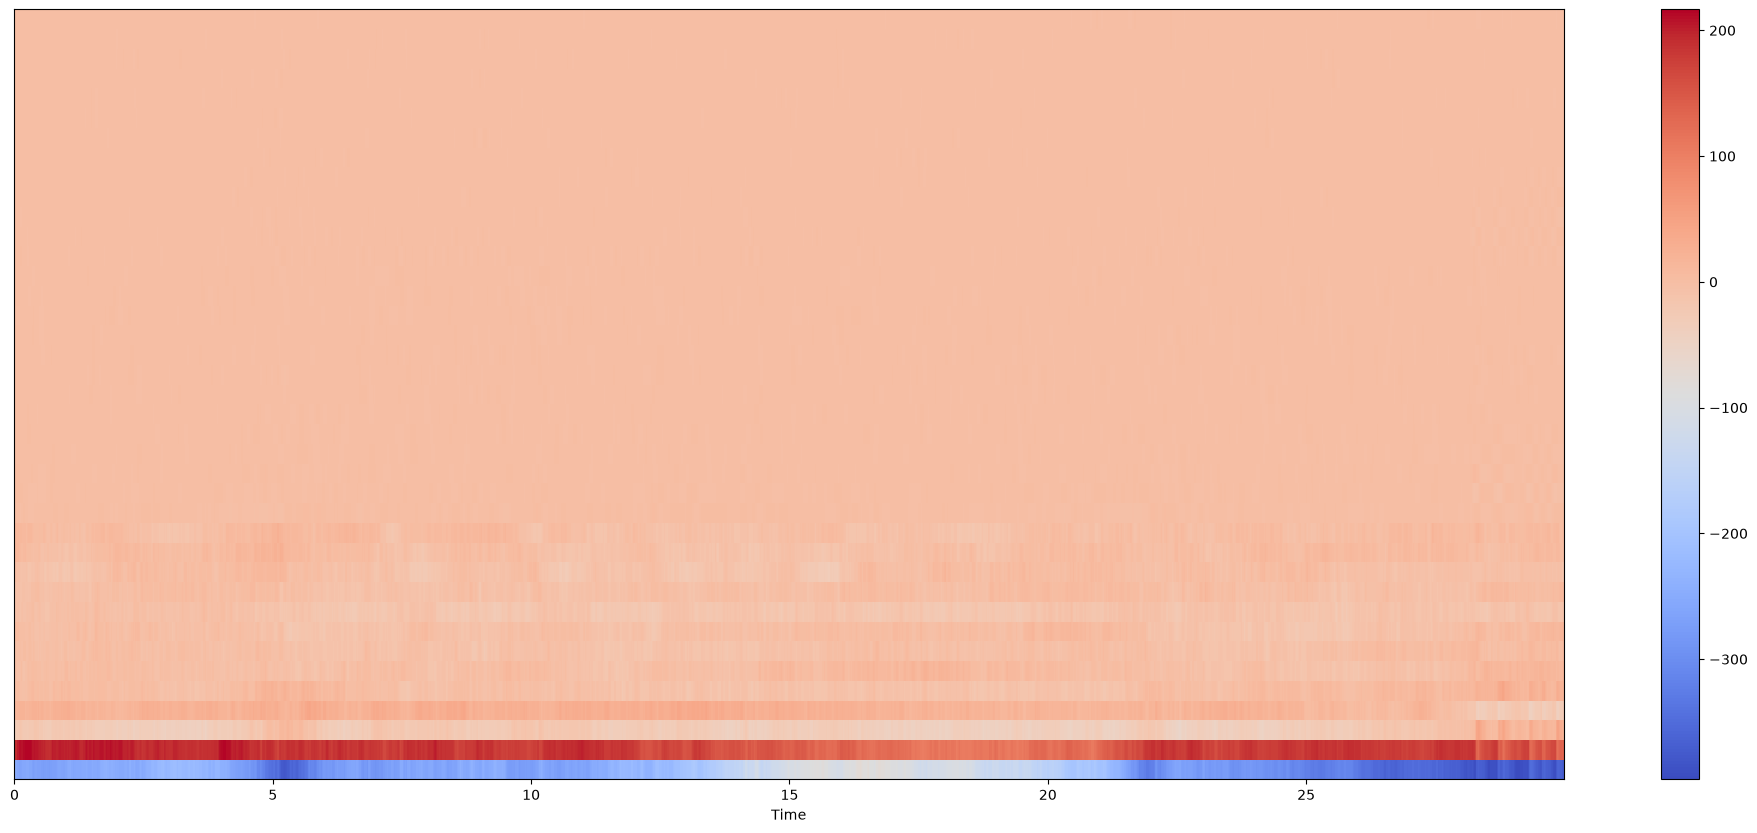

In [15]:
n_mfcc = 13

mfccs = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=n_mfcc)
d = librosa.feature.delta(mfccs)
d2 = librosa.feature.delta(mfccs, order=2)
c_mfccs = np.concatenate((mfccs, d, d2))

plt.figure(figsize=(25,10))
librosa.display.specshow(c_mfccs, sr=sr, hop_length=hop_size, x_axis="time")
plt.colorbar()
plt.show()